# 02c · Does a cross-regional bottleneck cost more than a within-regional one, at matched parameters?

*Follows task 02's rank grid. Answers one question task 02's own marginals cannot: not
"which rank binds first" -- three cross blocks to one within block means cross always
binds first by counting alone -- but whether cross-region rank is a more valuable place to
spend a fixed weight budget than within-region rank.*

**Why this is not task 02's dense-side marginals.** Section 1 below works the arithmetic:
holding one side fully dense and squeezing only the other cannot be made parameter-matched
in the regime that matters, so this task bottlenecks *both* sides and matches cells by
total weight budget instead. Section 2 builds that matched grid; Section 3 is the only
place anything new gets trained, gated the same way task 02 gates it; Sections 4-6 are the
comparison, read against the noise ceiling, per fixation type, and per frequency band.

| Section | |
|---|---|
| 1 | The parameter-counting problem with a dense side |
| 2 | Matching both sides: the budget grid |
| 3 | Run state and submission (off by default) |
| 4 | Fit at matched budget: worst cell and per condition |
| 5 | Which fixation type costs the most |
| 6 | Which frequency band costs the most |
| 7 | Reading the result |

**Nothing here submits a job unless `SUBMIT` is set to `True`.**

In [1]:
%load_ext autoreload
%autoreload 2

from __future__ import annotations

from pathlib import Path
import sys

import numpy as np
import pandas as pd
import yaml
from IPython.display import Image, Markdown, display

repo_root = Path.cwd()
if not (repo_root / "src").exists():
    repo_root = next(parent for parent in Path.cwd().parents if (parent / "src").exists())
if str(repo_root / "src") not in sys.path:
    sys.path.insert(0, str(repo_root / "src"))

from dal_monte_2022_analysis.config.load import load_config
from dal_monte_2022_analysis.ephys.analysis import fixation_mrnn_audit as audit
from dal_monte_2022_analysis.ephys.analysis import fixation_mrnn_protocol as protocol
from dal_monte_2022_analysis.ephys.analysis import fixation_mrnn_sweep as sweep
from dal_monte_2022_analysis.ephys.analysis import fixation_psth_noise_ceiling as ceiling_mod
from dal_monte_2022_analysis.ephys.plotting import fixation_mrnn_audit as aviz
from dal_monte_2022_analysis.ephys.plotting.thesis_common import (
    ThesisFigureSettings, apply_thesis_plot_style, figure_to_png_bytes, save_thesis_figure,
)

DATASET_CFG_PATH = repo_root / "configs" / "dataset.yaml"
MRNN_CFG_PATH = repo_root / "configs" / "ephys_fixation_mrnn.yaml"
apply_thesis_plot_style(load_config(repo_root / "configs" / "plotting.yaml"))

TREE = "final"
# Same root as task 02: these are more cells of the same rank grid, not a new sweep tree.
TASK_ROOT = sweep.resolve_task_root("02_rank_grid", DATASET_CFG_PATH, tree=TREE)
LADDER_ROOT = sweep.resolve_task_root("01_ladder", DATASET_CFG_PATH, tree=TREE)
CEILING_DIR = ceiling_mod.resolve_output_dir(DATASET_CFG_PATH)
FIGURE_DIR = TASK_ROOT.parent.parent / "plots" / "final_02c_within_vs_cross_bottleneck"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
FIGURES = ThesisFigureSettings(output_dir=FIGURE_DIR)
TABLE_DIR = TASK_ROOT.parent / "02c_within_vs_cross_bottleneck" / "tables"
TABLE_DIR.mkdir(parents=True, exist_ok=True)

SELECTED_PROTOCOL, PROTOCOL_IS_PROVISIONAL = sweep.load_selected_protocol_or_provisional(
    protocol.resolve_chapter_root(DATASET_CFG_PATH, task="00_training_protocol") / "selected_protocol.yaml")
BASE = yaml.safe_load((TASK_ROOT.parent / "base_model.yaml").read_text())
REGION_ORDER = tuple(BASE.pop("region_order"))
BASE.pop("inherited_protocol", None); BASE.pop("r2_centring", None)
HIDDEN_UNITS = int(BASE["hidden_units"])
N_REGIONS = len(REGION_ORDER)

ORIGINAL_RANKS = (1, 2, 3, 5, 10)
EXTENDED_RANKS = (1, 2, 3, 4, 5, 10)
GRID_SEEDS = 5
SEEDS = protocol.protocol_seeds(n_seeds=GRID_SEEDS)

_cell_path = TASK_ROOT.parent / "pc_space_ceiling_by_cell.csv"
if _cell_path.exists():
    _cell = pd.read_csv(_cell_path)
    ceiling_by_region = _cell[_cell["condition"] == "all"].set_index("region")["reliability"].to_dict()
    ceiling_by_cell = {(r, c): v for r, c, v in _cell[_cell["condition"] != "all"]
                       [["region", "condition", "reliability"]].itertuples(index=False)}
else:
    ceiling_by_region = (pd.read_csv(CEILING_DIR / "pc_space_ceiling.csv")
                         .groupby("region")["reliability"].mean().to_dict())
    ceiling_by_cell = None


def show(figure, stem: str) -> None:
    save_thesis_figure(figure, FIGURES, stem)
    display(Image(data=figure_to_png_bytes(figure, dpi=190)))


def cached(name: str, build):
    path = TABLE_DIR / f"{name}.csv"
    if path.exists():
        return pd.read_csv(path)
    frame = build()
    path.parent.mkdir(parents=True, exist_ok=True)
    frame.to_csv(path, index=False)
    return frame


print("task root (shared with 02):", TASK_ROOT)
print("table dir               :", TABLE_DIR)

task root (shared with 02): /gpfs/milgram/pi/chang/pg496/repositories/local_data/dal_monte_2022/analysis_outputs/ephys/modeling/fixation_mrnn/final/02_rank_grid
table dir               : /gpfs/milgram/pi/chang/pg496/repositories/local_data/dal_monte_2022/analysis_outputs/ephys/modeling/fixation_mrnn/final/02c_within_vs_cross_bottleneck/tables


## 1. The parameter-counting problem with a dense side

Every region has the same width $h=40$. A within-region block factored at rank $r_w$ costs
$2\,r_w\,h$ parameters; one per region, 4 regions: **$320\,r_w$** total. A cross-region
block factored at rank $r_c$ costs $2\,r_c\,h$; one per ordered pair, and full connectivity
on 4 regions has $4\times3=12$ ordered pairs: **$960\,r_c$** total. The ratio is exactly 3,
for any $h$ -- it is the count of other regions, not a property of the rank.

A **dense** within block is $h\times h=1600$ per region, **6400** total; a dense cross
block is $12\times1600=$ **19200** total -- three times as much, same reasoning.

So "cross bottlenecked, within dense" costs $6400+960\,r_c$ and "within bottlenecked, cross
dense" costs $320\,r_w+19200$. Matched parameter counts means

$$960\,r_c = 320\,r_w + 12800 \quad\Longleftrightarrow\quad r_c = \tfrac{r_w}{3} + 13.3,$$

which has no solution with $r_c<14$ for *any* $r_w\geq1$ -- a dense cross block alone
already outweighs a severely bottlenecked within block plus a dense within block combined.
Matching this comparison would force the cross side to sit at $r_c\approx14$-$27$, i.e.
35-70% of full rank, while the within side ranges over its whole severe-bottleneck regime:
not a fair comparison of two bottlenecks, but of a mild cross constraint against a genuine
one. There is no pair in the regime where *both* sides are actually constrained.

The cell below grounds the two block costs in measured parameter counts (not just the
formula) using :func:`sweep.count_trainable_parameters` on checkpoints already on disk, then
Section 2 drops the dense side entirely.

In [2]:
example_cells = {
    "w1_c1 (both bottlenecked)": TASK_ROOT / "w1_c1",
    "w1_cdense (cross dense)": TASK_ROOT / "w1_cdense",
    "wdense_c1 (within dense)": TASK_ROOT / "wdense_c1",
    "full (both dense)": LADDER_ROOT / "full",
}
rows = []
for label, path in example_cells.items():
    seed_dirs = audit.seed_run_dirs(path)
    if not seed_dirs:
        continue
    counts = sweep.count_trainable_parameters(seed_dirs[0])
    rows.append({"label": label, "within_region (incl. 'other')": counts["within_region"] + counts["other"],
                "inter_region": counts["inter_region"], "total_recurrent":
                counts["within_region"] + counts["other"] + counts["inter_region"]})
measured = pd.DataFrame(rows)
display(Markdown(
    "`within_region` is folded into `count_trainable_parameters`'s `other` bucket for the "
    "low-rank case (it only names the dense-branch parameter), so the two are summed here."))
display(measured)

r_c_grid = pd.DataFrame({"r_w": [1, 2, 3, 5, 10, 20]})
r_c_grid["matched r_c (cross dense side)"] = r_c_grid["r_w"] / 3 + 12800 / 960
display(Markdown("**Matched $r_c$ for 'within bottlenecked, cross dense' against 'cross "
                 "bottlenecked, within dense', by $r_w$:**"))
display(r_c_grid.round(2))

`within_region` is folded into `count_trainable_parameters`'s `other` bucket for the low-rank case (it only names the dense-branch parameter), so the two are summed here.

,label,within_region (incl. 'other'),inter_region,total_recurrent
0,w1_c1 (both bottlenecked),320,960,1280
1,w1_cdense (cross dense),320,19200,19520
2,wdense_c1 (within dense),6400,960,7360
3,full (both dense),6400,19200,25600


**Matched $r_c$ for 'within bottlenecked, cross dense' against 'cross bottlenecked, within dense', by $r_w$:**

,r_w,matched r_c (cross dense side)
0,1,13.67
1,2,14.00
2,3,14.33
3,5,15.00
4,10,16.67
5,20,20.00


## 2. Matching both sides: the budget grid

No dense arm. Every configuration bottlenecks within at $r_w$ and cross at $r_c$; its
**budget** is $r_w + 3\,r_c$, proportional to its total recurrent-weight count (the fixed
$320$-per-unit scale cancels in any comparison). Two configurations sharing a budget spend
it differently -- more on within, more on cross -- which is the matched comparison this
task runs. `cross_budget_fraction` is the share of the budget spent cross-region: 0 is all
within, 1 is all cross.

Task 02's grid used $r\in\{1,2,3,5,10\}$; adding **$r=4$** closes enough of the gap to
match every configuration already on disk against a genuine opposite-heavy partner at the
same budget, without a wide new rank sweep. Budgets reached by three configurations (13 and
16, below) also show the interior point for context, though the paired contrast in Sections
4-6 only ever uses the two extremes -- the largest within-vs-cross contrast the budget
allows.

In [3]:
groups = audit.matched_budget_groups(EXTENDED_RANKS, n_regions=N_REGIONS)
extremes = audit.matched_budget_extremes(groups)

existing_labels = {f"w{w}_c{c}" for w in ORIGINAL_RANKS for c in ORIGINAL_RANKS}
groups["already_trained"] = groups["label"].isin(existing_labels)
display(Markdown(f"**{len(groups)} matched configurations across {groups['budget'].nunique()} "
                 f"budgets** ({int(groups['already_trained'].sum())} already on disk from task "
                 f"02, {int((~groups['already_trained']).sum())} new at rank 4)."))
display(groups[["budget", "label", "rank_within", "rank_cross", "cross_budget_fraction", "already_trained"]]
       .sort_values(["budget", "cross_budget_fraction"]))

display(Markdown("**The paired extremes used in Sections 4-6:**"))
display(extremes)

needed_labels = sorted(set(extremes["within_heavy_label"]) | set(extremes["cross_heavy_label"]))
new_labels = [l for l in needed_labels if l not in existing_labels]
display(Markdown(f"**New training required:** {len(new_labels)} configurations x {GRID_SEEDS} "
                 f"seeds = {len(new_labels) * GRID_SEEDS} runs -- {', '.join(new_labels)}."))

**20 matched configurations across 9 budgets** (12 already on disk from task 02, 8 new at rank 4).

,budget,label,rank_within,rank_cross,cross_budget_fraction,already_trained
0,7,w4_c1,4,1,0.428571,False
1,7,w1_c2,1,2,0.857143,True
2,8,w5_c1,5,1,0.375000,True
3,8,w2_c2,2,2,0.750000,True
4,10,w4_c2,4,2,0.600000,False
5,10,w1_c3,1,3,0.900000,True
6,11,w5_c2,5,2,0.545455,True
7,11,w2_c3,2,3,0.818182,True
8,13,w10_c1,10,1,0.230769,True
9,13,w4_c3,4,3,0.692308,False


**The paired extremes used in Sections 4-6:**

,budget,within_heavy_label,within_heavy_rank_within,within_heavy_rank_cross,cross_heavy_label,cross_heavy_rank_within,cross_heavy_rank_cross
0,7,w4_c1,4,1,w1_c2,1,2
1,8,w5_c1,5,1,w2_c2,2,2
2,10,w4_c2,4,2,w1_c3,1,3
3,11,w5_c2,5,2,w2_c3,2,3
4,13,w10_c1,10,1,w1_c4,1,4
5,14,w5_c3,5,3,w2_c4,2,4
6,16,w10_c2,10,2,w1_c5,1,5
7,17,w5_c4,5,4,w2_c5,2,5
8,19,w10_c3,10,3,w4_c5,4,5


**New training required:** 6 configurations x 5 seeds = 30 runs -- w1_c4, w2_c4, w4_c1, w4_c2, w4_c5, w5_c4.

## 3. Run state and submission

Only the `new_labels` configurations from Section 2 -- the rest of the extended grid is
already on disk. Same gate as task 02: nothing is queued unless `SUBMIT` is set to `True`
and this cell is rerun.

In [4]:
def _variant_for(label: str):
    r_w, r_c = label.removeprefix("w").split("_c")
    variants = audit.rank_grid_variants((int(r_w), int(r_c)), base_overrides=BASE, include_marginals=False)
    return next(v for v in variants if v.label == label)

new_variants = [_variant_for(label) for label in new_labels]

SUBMIT = False   # <-- set to True to queue every missing run as one array

flight = sweep.in_flight_run_dirs(TASK_ROOT / "_jobs")
commands, _ = sweep.variant_job_commands(
    new_variants, SEEDS, root=TASK_ROOT, repo_root=repo_root,
    protocol=SELECTED_PROTOCOL, mrnn_cfg_path=MRNN_CFG_PATH, exclude_run_dirs=flight["run_dirs"])
inventory = sweep.index_variant_runs(TASK_ROOT, new_variants, SEEDS, in_flight=flight["run_dirs"])
display(Markdown(
    f"**{int(inventory['complete'].sum())} complete**, **{int(inventory['queued'].sum())} queued**, "
    f"**{int(inventory['pending'].sum())} unqueued** of {len(inventory)} new-configuration runs."))

if SUBMIT and commands:
    from datetime import datetime
    from dal_monte_2022_analysis.runtime.hpc.jobs import submit_dsq_array_job, write_job_file

    jobs_dir = TASK_ROOT / "_jobs"
    jobs_dir.mkdir(parents=True, exist_ok=True)
    stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    job_file = jobs_dir / f"within_vs_cross_{stamp}.txt"
    write_job_file(job_file, commands)
    submitted = [Path(line.split("--run-dir ")[1].split()[0]) for line in commands]
    job_id = submit_dsq_array_job(
        job_file_path=job_file, sbatch_script_path=jobs_dir / f"within_vs_cross_{stamp}.sh",
        log_dir=jobs_dir / "logs", job_name="mrnn_within_vs_cross", partition="psych_gpu",
        cpus_per_task=1, mem_per_cpu="12G", time_limit="06:00:00", gres="gpu:1",
    )
    sweep.record_submission(jobs_dir, job_id=job_id, run_dirs=submitted, label=f"within vs cross {stamp}")
    (jobs_dir / "job_id.txt").write_text(str(job_id) + "\n")
    display(Markdown(f"Submitted **{len(commands)}** runs as array **{job_id}**."))
elif commands:
    display(Markdown("`SUBMIT` is **False** -- nothing was submitted."))
else:
    display(Markdown("Every matched configuration is trained."))

**0 complete**, **0 queued**, **30 unqueued** of 30 new-configuration runs.

`SUBMIT` is **False** -- nothing was submitted.

## 4. Fit at matched budget: worst cell and per condition

All configurations in Section 2's grid, trained or not, so the panels below fill in as
Section 3's runs complete. `worst_cell` is the minimum region x condition $R^2$/ceiling per
seed -- the quantity the minimax objective actually optimised; the three condition panels
are its breakdown by fixation type, pooled over region.

**125** of **180** extended-grid runs complete.

,budget,condition,within_heavy_label,cross_heavy_label,n_seeds,within_heavy_mean,cross_heavy_mean,cross_minus_within,t_stat,p_value,p_holm,significant
0,8,face_interactive,w5_c1,w2_c2,5,0.9573,0.9598,0.0025,2.8727,0.0453,0.1360,False
1,8,face_non_interactive,w5_c1,w2_c2,5,0.9692,0.9717,0.0025,3.1074,0.0360,0.1079,False
2,8,object,w5_c1,w2_c2,5,0.9649,0.9675,0.0025,3.4557,0.0259,0.0778,False
3,8,worst_cell,w5_c1,w2_c2,5,0.9573,0.9598,0.0025,2.8727,0.0453,0.1360,False
4,11,face_interactive,w5_c2,w2_c3,5,0.9652,0.9664,0.0012,0.7640,0.4874,0.4874,False
5,11,face_non_interactive,w5_c2,w2_c3,5,0.9759,0.9767,0.0008,0.6261,0.5652,0.6846,False
6,11,object,w5_c2,w2_c3,5,0.9718,0.9729,0.0010,0.8168,0.4599,0.6336,False
7,11,worst_cell,w5_c2,w2_c3,5,0.9652,0.9664,0.0012,0.7640,0.4874,0.4874,False
8,16,face_interactive,w10_c2,w1_c5,5,0.9711,0.9726,0.0015,1.5877,0.1876,0.3751,False
9,16,face_non_interactive,w10_c2,w1_c5,5,0.9809,0.9818,0.0008,1.0765,0.3423,0.6846,False


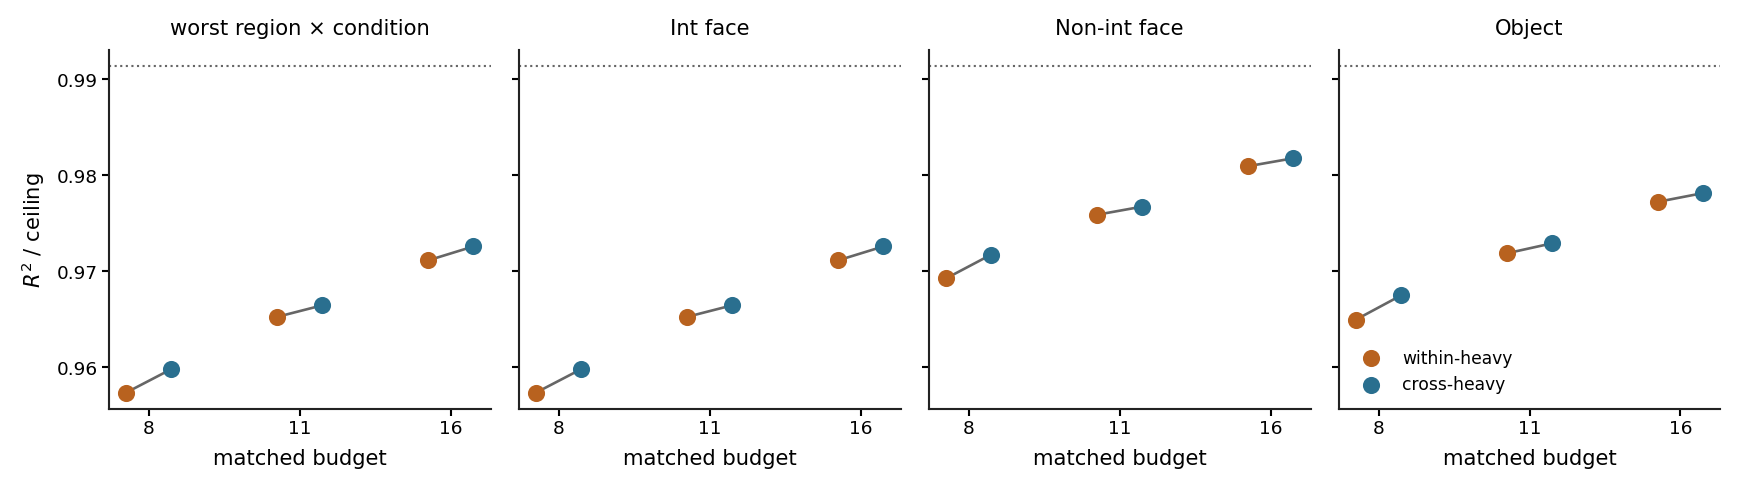

In [5]:
all_variants = audit.rank_grid_variants(EXTENDED_RANKS, base_overrides=BASE, include_marginals=False)
all_inventory = sweep.index_variant_runs(TASK_ROOT, all_variants, SEEDS)
done = all_inventory[all_inventory["complete"]]
display(Markdown(f"**{int(done.shape[0])}** of **{all_inventory.shape[0]}** extended-grid runs complete."))

if done.empty:
    fit = fit_contrast = None
else:
    fit = cached("extended_grid_fit", lambda: sweep.score_variant_fit(done, ceiling_by_region, ceiling_by_cell=ceiling_by_cell))
    fit_contrast = audit.matched_budget_fit_contrast(fit, extremes)
    display(fit_contrast.round(4))

    full_dirs = audit.seed_run_dirs(LADDER_ROOT / "full")
    dense_value = None
    if full_dirs:
        full_inv = pd.DataFrame([{"label": "full", "seed": p.name.replace("seed=", ""), "run_dir": str(p),
                                  "complete": True} for p in full_dirs])
        full_fit = sweep.score_variant_fit(full_inv, ceiling_by_region, ceiling_by_cell=ceiling_by_cell)
        dense_value = float(full_fit.groupby("seed")["r2_vs_ceiling"].min().mean())

    show(aviz.plot_matched_budget_contrast(fit_contrast, dense_value=dense_value), "fig01_matched_budget_contrast")

## 5. Which fixation type costs the most

The same contrast, read across the three condition panels of Section 4 rather than down
one: is the within-vs-cross gap the same size in every fixation type, or does it
concentrate in one -- consistent with interactive face already being the hardest condition
for the dense model itself.

In [6]:
if fit_contrast is not None and not fit_contrast.empty:
    by_condition = (fit_contrast[fit_contrast["condition"] != "worst_cell"]
                    .groupby("condition")[["cross_minus_within"]].mean()
                    .rename(columns={"cross_minus_within": "mean cross-within gap"}))
    by_condition["n_significant_budgets"] = (
        fit_contrast[fit_contrast["condition"] != "worst_cell"]
        .groupby("condition")["significant"].sum())
    display(by_condition.round(4))

,mean cross-within gap,n_significant_budgets
condition,,
face_interactive,0.0017,0
face_non_interactive,0.0014,0
object,0.0015,0


## 6. Which frequency band costs the most

Per-condition, per-band residual fraction (target power the fit fails to reproduce),
contrasted the same way: within-heavy vs. cross-heavy at matched budget. Bands follow the
ladder's own split (Nyquist 50 Hz at 10 ms bins); `band_resolved_recovery_by_condition` is
the per-condition counterpart of the function the ladder notebook already uses pooled over
condition.

In [7]:
if done.empty:
    band_contrast = None
else:
    band_by_condition = cached("band_recovery_by_condition", lambda: pd.concat(
        [audit.band_resolved_recovery_by_condition(r.run_dir).assign(label=r.label) for r in done.itertuples()],
        ignore_index=True))
    band_contrast = audit.matched_budget_band_contrast(band_by_condition, extremes)
    display(band_contrast.round(4))
    show(aviz.plot_matched_budget_band_contrast(band_contrast), "fig02_matched_budget_band_contrast")

,budget,condition,band,within_heavy_label,cross_heavy_label,n_seeds,within_heavy_mean,cross_heavy_mean,cross_minus_within,t_stat,p_value,p_holm,significant
0,8,face_interactive,0-5 Hz,w5_c1,w2_c2,5,0.0466,0.0410,-0.0056,-1.5803,0.1892,1.0000,False
1,8,face_interactive,10-20 Hz,w5_c1,w2_c2,5,0.8712,0.8713,0.0001,0.0112,0.9916,1.0000,False
2,8,face_interactive,20-50 Hz,w5_c1,w2_c2,5,0.3880,0.3687,-0.0193,-0.7733,0.4825,1.0000,False
3,8,face_interactive,5-10 Hz,w5_c1,w2_c2,5,0.6217,0.5928,-0.0289,-1.5919,0.1866,1.0000,False
4,8,face_non_interactive,0-5 Hz,w5_c1,w2_c2,5,0.0036,0.0045,0.0008,1.7913,0.1477,1.0000,False
5,8,face_non_interactive,10-20 Hz,w5_c1,w2_c2,5,0.7718,0.7337,-0.0381,-2.6057,0.0597,0.7163,False
6,8,face_non_interactive,20-50 Hz,w5_c1,w2_c2,5,0.3127,0.3014,-0.0113,-0.9811,0.3821,1.0000,False
7,8,face_non_interactive,5-10 Hz,w5_c1,w2_c2,5,0.1210,0.1083,-0.0127,-2.3937,0.0749,0.8235,False
8,8,object,0-5 Hz,w5_c1,w2_c2,5,0.0044,0.0039,-0.0005,-0.8436,0.4464,1.0000,False
9,8,object,10-20 Hz,w5_c1,w2_c2,5,0.7620,0.7319,-0.0301,-1.5451,0.1972,1.0000,False


## 7. Reading the result

**The headline comparison.** Section 4's `worst_cell` panel, read budget by budget: a
downward slope from within-heavy to cross-heavy is cross rank costing more fit than within
rank at the same parameter count; Holm-significant budgets are marked.

**Which fixation type carries it.** Section 5. If the gap concentrates in interactive face,
it is the same failure the dense model already shows (`fixation_mrnn_target_loss.py`:
roughly half the target energy, most of the residual) made worse by a cross bottleneck
specifically, not a new finding about fixation type in general.

**Which frequency band carries it.** Section 6. The prediction, following the dense model's
own band recovery, is that the gap -- if there is one -- sits in 10-20 Hz and climbs with
budget, not in the slow 0-5 Hz band every configuration already reproduces.

**If more budgets would sharpen the claim.** Section 2/3's `new_labels` is driven entirely
by `EXTENDED_RANKS`; adding ranks 6-9 the same way extends the budget ladder with no change
to Sections 4-6, which read whatever :func:`matched_budget_groups` finds.